# 01 — Understand the data and protect the evaluation boundary

**Stage 1 only. No model is trained in this notebook.**

We ask whether an existing card customer defaults next month, using the supplied
historical payment information. We assume scoring occurs after September 2005
information is available. Operational reporting lags and the precise default
definition are **[需要真实信息]**.

Source: [UCI Default of Credit Card Clients](https://doi.org/10.24432/C55S3H),
Yeh (2009), CC BY 4.0. This is a historical Taiwan sample, not a US loan-application dataset.

Run the preparation command in the README first. Then run cells from top to bottom.
This notebook calls reusable source instead of reimplementing data preparation.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from credit_risk.data import read_data, model_features

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Start from the project or notebooks directory'
audit = json.loads((ROOT / 'reports/data_audit.json').read_text(encoding='utf-8'))
provenance = json.loads((ROOT / 'data/raw/source.json').read_text(encoding='utf-8'))
display(pd.Series({k: provenance[k] for k in ['dataset', 'source_url', 'license', 'retrieved_utc', 'xls_sha256']}))

dataset                         UCI Default of Credit Card Clients
source_url       https://archive.ics.uci.edu/static/public/350/...
license                                                  CC BY 4.0
retrieved_utc                     2026-10-21T01:30:56.380967+00:00
xls_sha256       30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369...
dtype: str

## 1. Structural validation and fixed partition IDs

The loader rejects invalid targets, repeated IDs, missing/nonfinite values, and unexpected
columns. It reads the second XLS row as the actual header. It does not interpret
undocumented category codes. Structural checks cover the whole file; descriptive
analysis below uses training data only.

The saved manifest contains IDs and partition names, not outcomes. Stratification
uses labels to create comparable partitions. Sorting IDs before assignment ensures
reproducibility under row reorder; it does **not** establish chronological order.

In [2]:
frame = read_data(ROOT / 'data/raw/source.xls')
manifest = pd.read_csv(ROOT / 'data/processed/split_manifest.csv')
display(pd.Series(audit['structural'], name='Observed structural checks'))
train_ids = manifest.loc[manifest['split'] == 'train', 'ID']
train = frame.loc[frame['ID'].isin(train_ids)].copy()
assert len(train) == audit['training']['rows']
# No validation/test label distribution or feature summary is displayed.
del frame
display(pd.DataFrame({'rows': manifest.groupby('split').size()}))

rows                                                                                    30000
source_predictors                                                                          23
model_predictors                                                                           21
missing_cells                                                                               0
duplicate_ids                                                                               0
duplicate_rows_beyond_first_excluding_id                                                   35
duplicate_source_profiles_beyond_first                                                     56
model_profiles_shared_across_partitions                                                    59
split_rows                                  {'test': 6000, 'train': 18000, 'validation': 6...
Name: Observed structural checks, dtype: object

,rows
split,
test,6000
train,18000
validation,6000


## 2. Understand the training label

Positive class 1 is the supplied next-month default label. Its observed training
frequency is a descriptive fact, not a model score. Accuracy alone can be misleading
when most customers belong to the negative class. Later stages will compare
ROC-AUC and average precision, plus precision/recall at explicit thresholds.

rows            18000.000000
defaults         3982.000000
non_defaults    14018.000000
default_rate        0.221222
dtype: float64

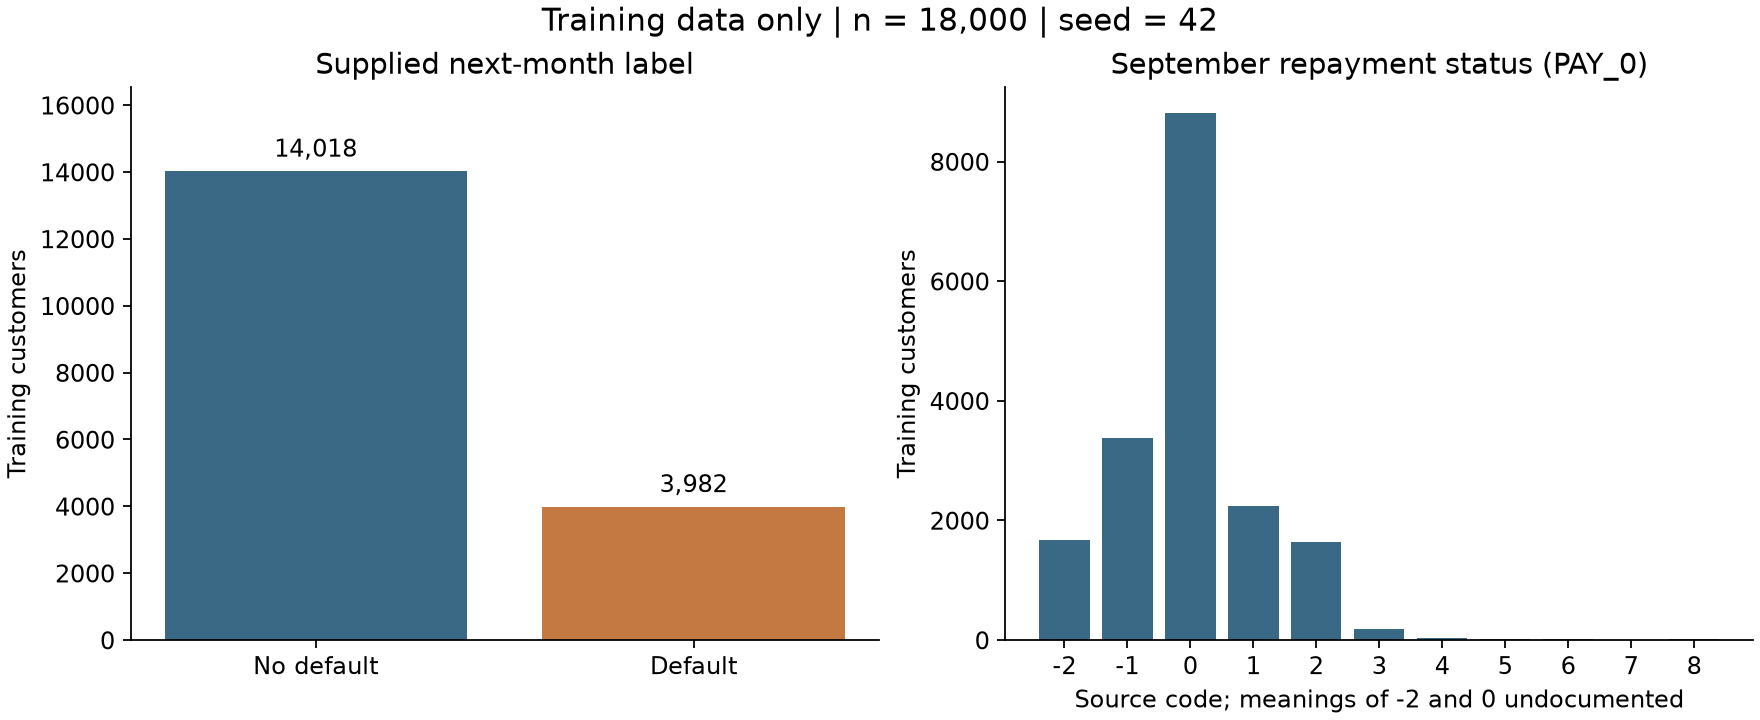

In [3]:
display(pd.Series({k: audit['training'][k] for k in ['rows', 'defaults', 'non_defaults', 'default_rate']}))
display(Image(filename=str(ROOT / 'reports/figures/training_overview.png')))

## 3. Codes are not automatically numeric quantities

`PAY_0` is September repayment status; `PAY_2` is August. The naming is preserved.
UCI documents -1 and positive delay codes, but not -2 or 0 in the repayment-code
description. Their interpretation is **[需要真实信息]**. Preserve those as explicit
categories. Education codes outside 1–4 are also not assigned invented meanings.
Negative bill amounts are retained rather than silently treated as errors.

In [4]:
for column in ['EDUCATION', 'PAY_0']:
    counts = train[column].value_counts().sort_index()
    display(counts.rename_axis(column).to_frame('training_customers'))
display(train[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].describe().round(2))

,training_customers
EDUCATION,
0,12
1,6338
2,8438
3,2928
4,72
5,181
6,31


,training_customers
PAY_0,
-2,1666
-1,3383
0,8805
1,2245
2,1635
3,184
4,41
5,12
6,9


,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
count,18000.00,18000.00,18000.00,18000.00
mean,167730.67,35.42,51473.41,5685.20
std,129767.65,9.16,73956.51,16898.34
min,10000.00,21.00,-165580.00,0.00
25%,50000.00,28.00,3594.00,1000.00
50%,140000.00,34.00,22344.50,2138.50
75%,240000.00,41.00,67571.00,5045.75
max,1000000.00,75.00,964511.00,873552.00


## 4. Predictor boundary and leakage

The explicit allowlist contains 21 predictors. ID and outcome are never predictors;
SEX and MARRIAGE are reserved for diagnostics. AGE remains a predictor. Excluding
some demographic fields does not prove fairness or eliminate proxy information.

Late-payment history can be valid because it precedes this scoring boundary.
Post-outcome collection amounts would be leakage. In the next stage, learned
preprocessing will be fit only on training data inside the model pipeline.

In [5]:
X_train = model_features(train)
display(pd.Series(X_train.columns, name='Allowed predictors'))
assert not {'ID', 'default', 'SEX', 'MARRIAGE'}.intersection(X_train.columns)
print('Predictors:', X_train.shape[1])

0     LIMIT_BAL
1           AGE
2     BILL_AMT1
3     BILL_AMT2
4     BILL_AMT3
5     BILL_AMT4
6     BILL_AMT5
7     BILL_AMT6
8      PAY_AMT1
9      PAY_AMT2
10     PAY_AMT3
11     PAY_AMT4
12     PAY_AMT5
13     PAY_AMT6
14    EDUCATION
15        PAY_0
16        PAY_2
17        PAY_3
18        PAY_4
19        PAY_5
20        PAY_6
Name: Allowed predictors, dtype: str

Predictors: 21


## 5. Duplicate profiles and limitations

Different IDs can share financial profiles. Shared values alone do not prove that
two records represent the same customer. We retain distinct IDs and report
cross-partition profile overlap. Hidden duplicate identities remain a limitation;
do not claim that unique IDs prove perfect independence.

The random holdout describes this sampled setting. It is not a test of future
years, new economic conditions, US borrowers, intervention effectiveness or legal
compliance. Model metrics, calibrated probabilities and subgroup results are
**[需要真实信息]** until the remaining stages are run.

In [6]:
display(pd.Series({k: v for k, v in audit['structural'].items() if 'duplicate' in k or 'shared' in k}))
for limitation in audit['limits']:
    print('-', limitation)

duplicate_ids                                0
duplicate_rows_beyond_first_excluding_id    35
duplicate_source_profiles_beyond_first      56
model_profiles_shared_across_partitions     59
dtype: int64

- Historical Taiwan snapshot; no temporal or US-population validation.
- Distinct IDs with shared profiles retained; hidden entity duplication cannot be excluded.
- SEX and MARRIAGE audit-only; removing them does not establish fairness.
- Undocumented category semantics are not inferred.
- Model metrics and business impact: [需要真实信息].


## Explain this before continuing

1. At what point would a prediction be produced, and which fields are available then?
2. Why are the historical payment columns useful, while a future collection field is leakage?
3. Why are there separate validation and test partitions?
4. Why would fitting a scaler on the whole dataset cross the evaluation boundary?
5. What do the undocumented codes and duplicate profiles stop us from claiming?

**Next:** train-only preprocessing, logistic regression and a constant-probability
benchmark. Do not claim a trained model or an achieved AUC from this stage.